In [1]:
# Get companies from wikipedia

import bs4 as bs
import pickle
import requests

resp = requests.get('http://en.wikipedia.org/wiki/List_of_S%26P_500_companies')
soup = bs.BeautifulSoup(resp.text, 'lxml')
table = soup.find('table', {'class': 'wikitable sortable'})
tickers = []
for row in table.findAll('tr')[1:]:
    ticker = row.findAll('td')[0].text.replace('.', '-')
    ticker = ticker[:-1]
    tickers.append(ticker)
tickers.append('SPY')
with open("sp500tickers.pickle", "wb") as f:
    pickle.dump(tickers, f)

In [2]:
# Save stock prices from yahoo

import datetime as dt
import os
import pandas_datareader.data as pdr
import pickle
import yfinance as yf

with open("sp500tickers.pickle", "rb") as f:
    tickers = pickle.load(f)
if not os.path.exists('stock_dfs'):
    os.makedirs('stock_dfs')

# testing
start = dt.datetime(2000, 1, 1)
end = dt.datetime.now()

print("SPY")
if not os.path.exists('stock_dfs_yahoo/SPY.csv'):
    df = pdr.get_data_yahoo("SPY", start, end)
    df.reset_index(inplace=True)
    df.set_index("Date", inplace=True)
    df.to_csv('stock_dfs_yahoo/SPY.csv')
else:
    print('Already have SPY')

for ticker in tickers:
    print(ticker)
    if not os.path.exists('stock_dfs_yahoo/{}.csv'.format(ticker)):
        df = pdr.get_data_yahoo(ticker, start, end)
        df.reset_index(inplace=True)
        df.set_index("Date", inplace=True)
        df.to_csv('stock_dfs_yahoo/{}.csv'.format(ticker))
    else:
        print('Already have {}'.format(ticker))

SPY
Already have SPY
MMM
Already have MMM
ABT
Already have ABT
ABBV
Already have ABBV
ABMD
Already have ABMD
ACN
Already have ACN
ATVI
Already have ATVI
ADBE
Already have ADBE
AMD
Already have AMD
AAP
Already have AAP
AES
Already have AES
AFL
Already have AFL
A
Already have A
APD
Already have APD
AKAM
Already have AKAM
ALK
Already have ALK
ALB
Already have ALB
ARE
Already have ARE
ALXN
Already have ALXN
ALGN
Already have ALGN
ALLE
Already have ALLE
LNT
Already have LNT
ALL
Already have ALL
GOOGL
Already have GOOGL
GOOG
Already have GOOG
MO
Already have MO
AMZN
Already have AMZN
AMCR
Already have AMCR
AEE
Already have AEE
AAL
Already have AAL
AEP
Already have AEP
AXP
Already have AXP
AIG
Already have AIG
AMT
Already have AMT
AWK
Already have AWK
AMP
Already have AMP
ABC
Already have ABC
AME
Already have AME
AMGN
Already have AMGN
APH
Already have APH
ADI
Already have ADI
ANSS
Already have ANSS
ANTM
Already have ANTM
AON
Already have AON
AOS
Already have AOS
APA
Already have APA
AIV
Alre

In [4]:
# compile data

import pandas as pd

with open("sp500tickers.pickle", "rb") as f:
    tickers = pickle.load(f)

# main_open_df = pd.DataFrame()
# main_close_df = pd.DataFrame()
main_daily_return_df = pd.DataFrame()

for count, ticker in enumerate(tickers):
    # open_df = pd.read_csv('stock_dfs/{}.csv'.format(ticker))
    # close_df = pd.read_csv('stock_dfs/{}.csv'.format(ticker))
    daily_return_df = pd.read_csv('stock_dfs_yahoo/{}.csv'.format(ticker))

    # open_df.set_index('Date', inplace=True)
    # close_df.set_index('Date', inplace=True)
    daily_return_df.set_index('Date', inplace=True)

    # open_df.rename(columns={'Open': ticker}, inplace=True)
    # open_df.drop(['High', 'Low', 'Close', 'Adj Close', 'Volume'], 1, inplace=True)

    # close_df.rename(columns={'Close': ticker}, inplace=True)
    # close_df.drop(['Open', 'High', 'Low', 'Adj Close', 'Volume'], 1, inplace=True)

    daily_return_df['Daily Return'] = (daily_return_df['Adj Close'] / daily_return_df['Open']) - 1
    daily_return_df.rename(columns={'Daily Return': ticker}, inplace=True)
    daily_return_df.drop(['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], 1, inplace=True)

#     if main_open_df.empty:
#         main_open_df = open_df
#     else:
#         main_open_df = main_open_df.join(open_df, how='outer')

#     if main_close_df.empty:
#         main_close_df = close_df
#     else:
#         main_close_df = main_close_df.join(close_df, how='outer')

    if main_daily_return_df.empty:
        main_daily_return_df = daily_return_df
    else:
        main_daily_return_df = main_daily_return_df.join(daily_return_df, how='outer')

    if count % 10 == 0:
        print(count)

# print(main_open_df.head())
# open_df = main_open_df
# main_open_df.to_csv('sp500_joined_opens.csv')
# print(main_close_df.head())
# close_df = main_close_df
# main_close_df.to_csv('sp500_joined_closes.csv')
print(main_daily_return_df.head())
daily_return_df = main_daily_return_df
main_daily_return_df.to_csv('sp500_joined_daily_returns_yahoo.csv')


0
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200
210
220
230
240
250
260
270
280
290
300
310
320
330
340
350
360
370
380
390
400
410
420
430
440
450
460
470
480
490
500
                 MMM       ABT  ABBV      ABMD  ACN      ATVI      ADBE  \
Date                                                                      
2000-01-03 -0.420879 -0.395606   NaN -0.014346  NaN -0.064721 -0.031990   
2000-01-04 -0.424806 -0.399022   NaN -0.037162  NaN -0.114259 -0.053371   
2000-01-05 -0.396778 -0.384488   NaN  0.054945  NaN -0.093212  0.044063   
2000-01-06 -0.370289 -0.371148   NaN  0.023050  NaN -0.114423 -0.002024   
2000-01-07 -0.401052 -0.373645   NaN -0.003472  NaN -0.089726  0.044336   

                 AMD  AAP       AES  ...       XEL       XRX      XLNX  XYL  \
Date                                 ...                                      
2000-01-03  0.035491  NaN -0.255485  ... -0.608536 -0.304356 -0.310023  NaN   
2000-01-04 -0.033058  NaN -0.256409  ... -0.

In [9]:
daily_return_df

,MMM,ABT,ABBV,ABMD,ACN,ATVI,ADBE,AMD,AAP,AES,...,XEL,XRX,XLNX,XYL,YUM,ZBRA,ZBH,ZION,ZTS,SPY
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-03,-0.420879,-0.395606,NaN,-0.014346,NaN,-0.064721,-0.031990,0.035491,NaN,-0.255485,...,-0.608536,-0.304356,-0.310023,NaN,-0.283451,-0.034815,NaN,-0.322457,NaN,-0.335147
2000-01-04,-0.424806,-0.399022,NaN,-0.037162,NaN,-0.114259,-0.053371,-0.033058,NaN,-0.256409,...,-0.587705,-0.358993,-0.290556,NaN,-0.268203,-0.014428,NaN,-0.303260,NaN,-0.340144
2000-01-05,-0.396778,-0.384488,NaN,0.054945,NaN,-0.093212,0.044063,0.032258,NaN,-0.224806,...,-0.580057,-0.291187,-0.297410,NaN,-0.259446,0.066588,NaN,-0.279348,NaN,-0.321987
2000-01-06,-0.370289,-0.371148,NaN,0.023050,NaN,-0.114423,-0.002024,0.032258,NaN,-0.228983,...,-0.598170,-0.322374,-0.341881,NaN,-0.260714,-0.041970,NaN,-0.269102,NaN,-0.331391
2000-01-07,-0.401052,-0.373645,NaN,-0.003472,NaN,-0.089726,0.044336,0.054767,NaN,-0.214733,...,-0.595659,-0.311802,-0.214726,NaN,-0.275959,-0.006455,NaN,-0.281024,NaN,-0.296027
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-11-30,-0.017295,0.004176,-0.005137,0.001388,0.000120,0.014811,-0.003187,0.061033,-0.010915,-0.025274,...,-0.003698,-0.047018,0.058622,-0.008779,-0.003766,-0.000159,-0.007455,-0.019563,-0.012925,-0.002122
2020-12-01,-0.021237,-0.006866,-0.009614,-0.014332,0.003022,-0.000125,-0.005934,0.004119,0.023747,-0.002904,...,0.011683,-0.006278,0.005517,-0.004614,-0.004680,-0.024788,-0.029171,0.013661,-0.001732,0.001231
2020-12-02,0.009339,-0.001477,0.009519,-0.011073,-0.004188,-0.007150,0.011752,0.009151,-0.018058,0.033203,...,0.007334,0.014324,0.008985,-0.000935,-0.008407,-0.009441,0.017130,0.040000,-0.012733,0.005400


<AxesSubplot:xlabel='Date'>

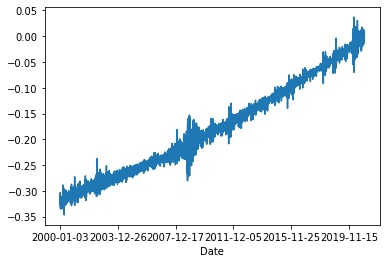

In [13]:
daily_return_df.mean(axis=1).plot()
# from scipy import stats
# import seaborn as sns
# import matplotlib.pyplot as plt
# from matplotlib import style

# sns.regplot(x=daily_return_df['SPY'].values, y=daily_return_df.mean(axis=1).values)
# plt.xlabel("SPY Returns")
# plt.ylabel("S&P500 Returns")
# plt.title("S&P500 on SPY")
# plt.show()

### SPY (market) variance ###

count    5257.000000
mean        0.000035
std         0.010014
min        -0.089906
25%        -0.004283
50%         0.000510
75%         0.004664
max         0.084347
Name: SPY, dtype: float64
variance: 0.00010028347949761257


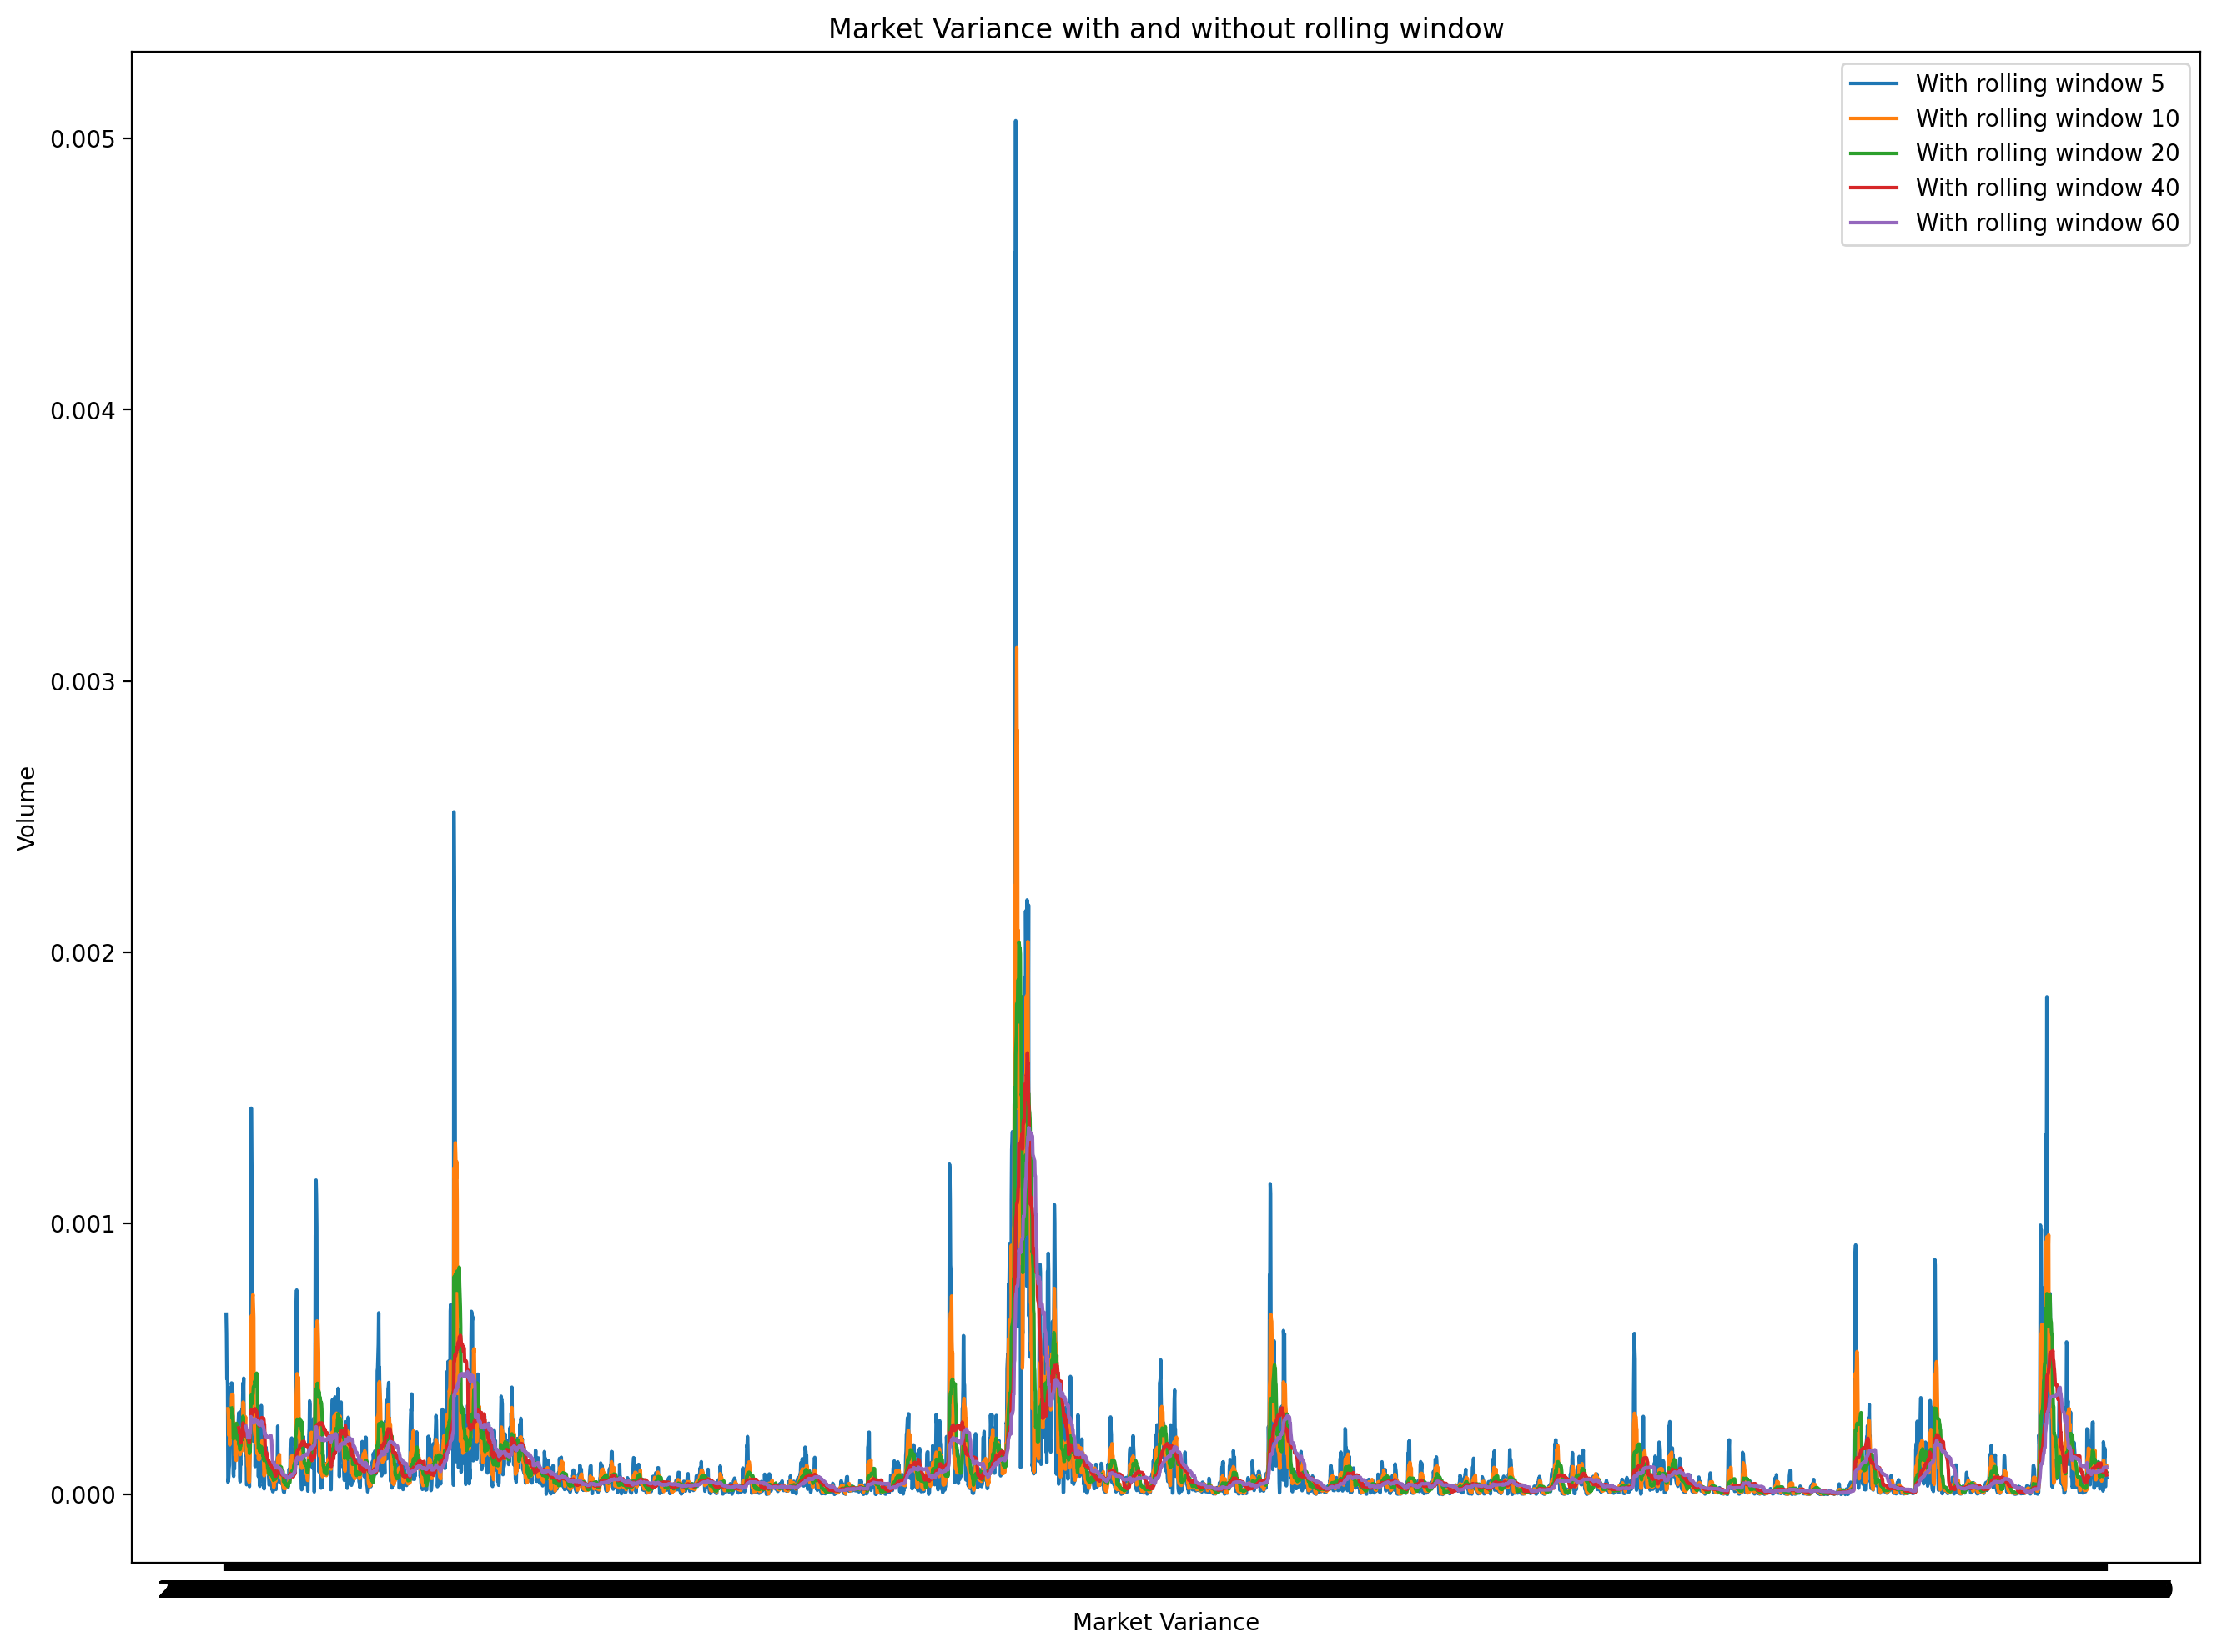

In [5]:
from matplotlib.pyplot import figure
print(daily_return_df['SPY'].describe())

figure(num=None, figsize=(16, 12), dpi=200, facecolor='w', edgecolor='k')

market_variance = daily_return_df['SPY'].var()
print("variance: {0}".format(market_variance))

for window in [5,10,20,40,60]:
    market_variance_roll = daily_return_df['SPY'].rolling(window).var()
    plt.plot(market_variance_roll, label = "With rolling window {0}".format(window))
    
plt.xlabel('Market Variance')
plt.ylabel('Volume')
plt.title("Market Variance with and without rolling window")
plt.legend()
plt.show()

### S&P500 Covariance ###

SP500 Covariance
count    505.000000
mean       0.000096
std        0.000029
min        0.000016
25%        0.000074
50%        0.000095
75%        0.000115
max        0.000228
dtype: float64


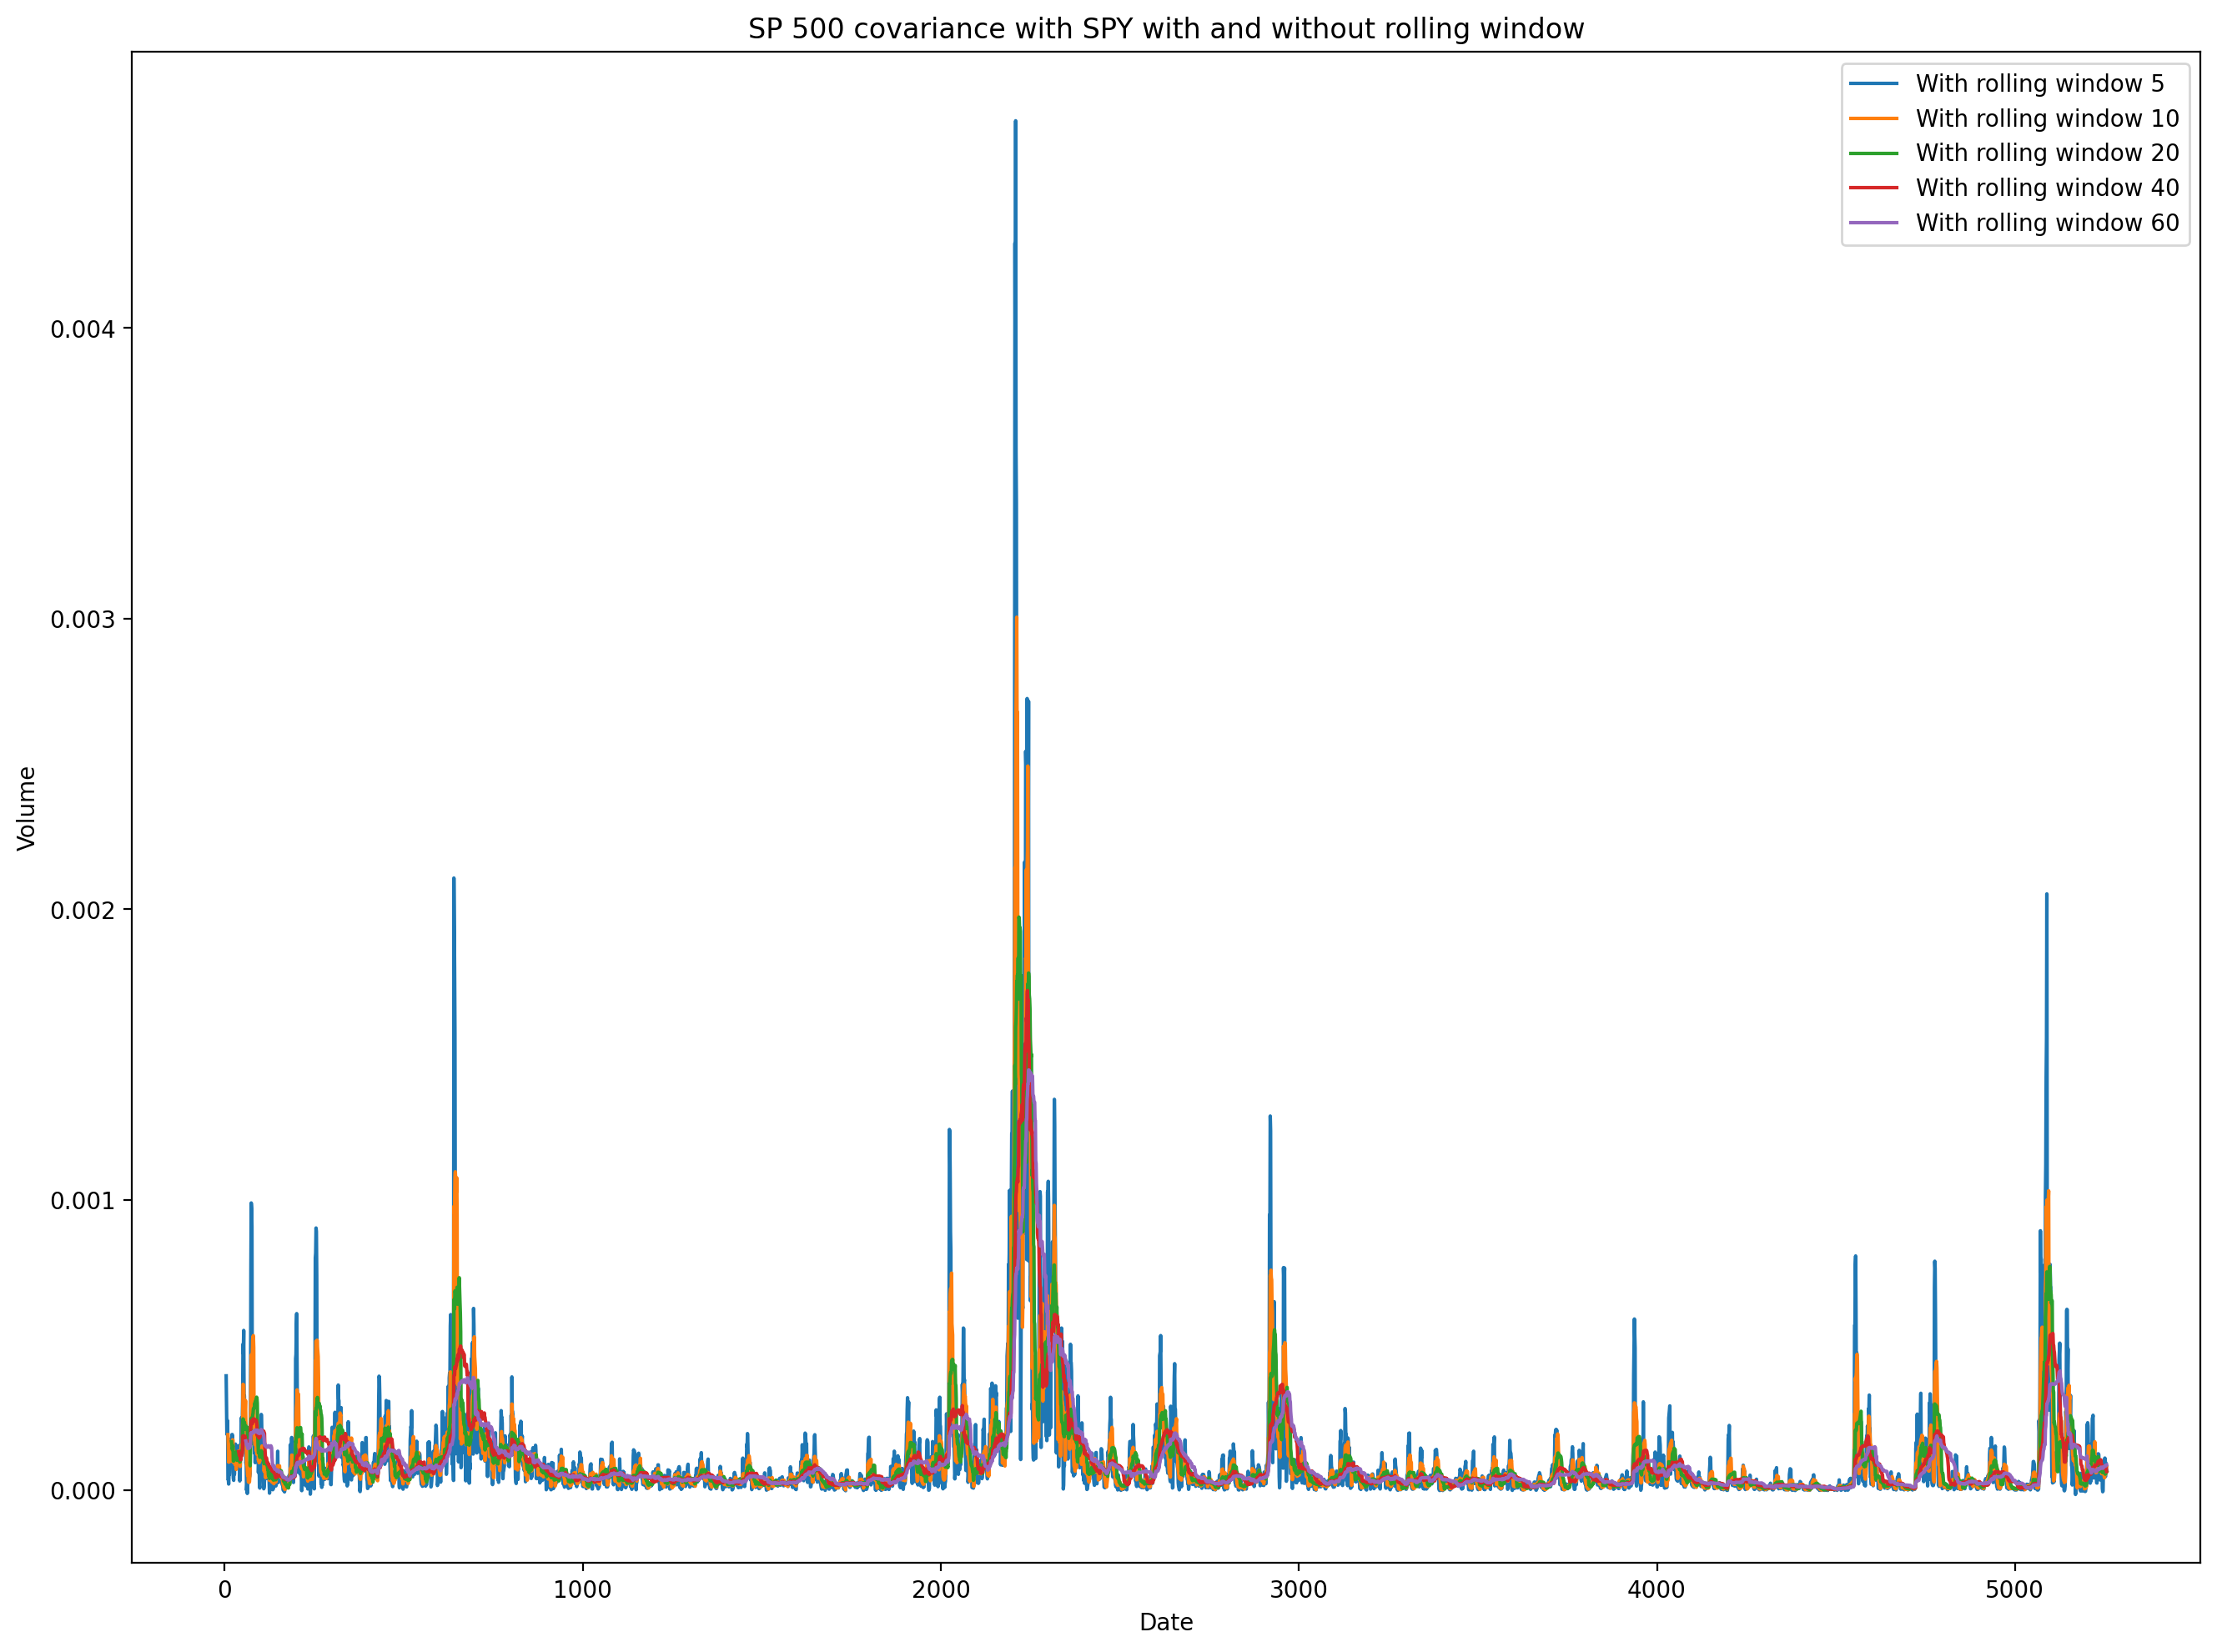

In [6]:
import pandas as pd
import datetime as dt

# without rolling window
SP_covariance = pd.Series({symbol: daily_return_df['SPY'].cov(daily_return_df[symbol]) 
               for symbol in tickers 
               if symbol != 'SPY'})
print("SP500 Covariance")
print(SP_covariance.describe())

figure(num=None, figsize=(16, 12), dpi=200, facecolor='w', edgecolor='k')

for window in [5,10,20,40,60]:
    SP_covariance_roll = pd.Series({symbol: daily_return_df['SPY'].rolling(window).cov(daily_return_df[symbol]).values
                            for symbol in tickers
                            if symbol != 'SPY'})
    SP_covariance_roll_df = pd.DataFrame(SP_covariance_roll.values.tolist(), index = SP_covariance_roll.index)
    plt.plot(SP_covariance_roll_df.mean(axis=0), label = "With rolling window {0}".format(window))

plt.xlabel('Date')
plt.ylabel('Volume')
plt.title("SP 500 covariance with SPY with and without rolling window")
plt.legend()
plt.show()

 ### Beta statistics ###

Beta without rolling window
count    505.000000
mean       0.955550
std        0.288996
min        0.160303
25%        0.739767
50%        0.947169
75%        1.145815
max        2.276302
dtype: float64


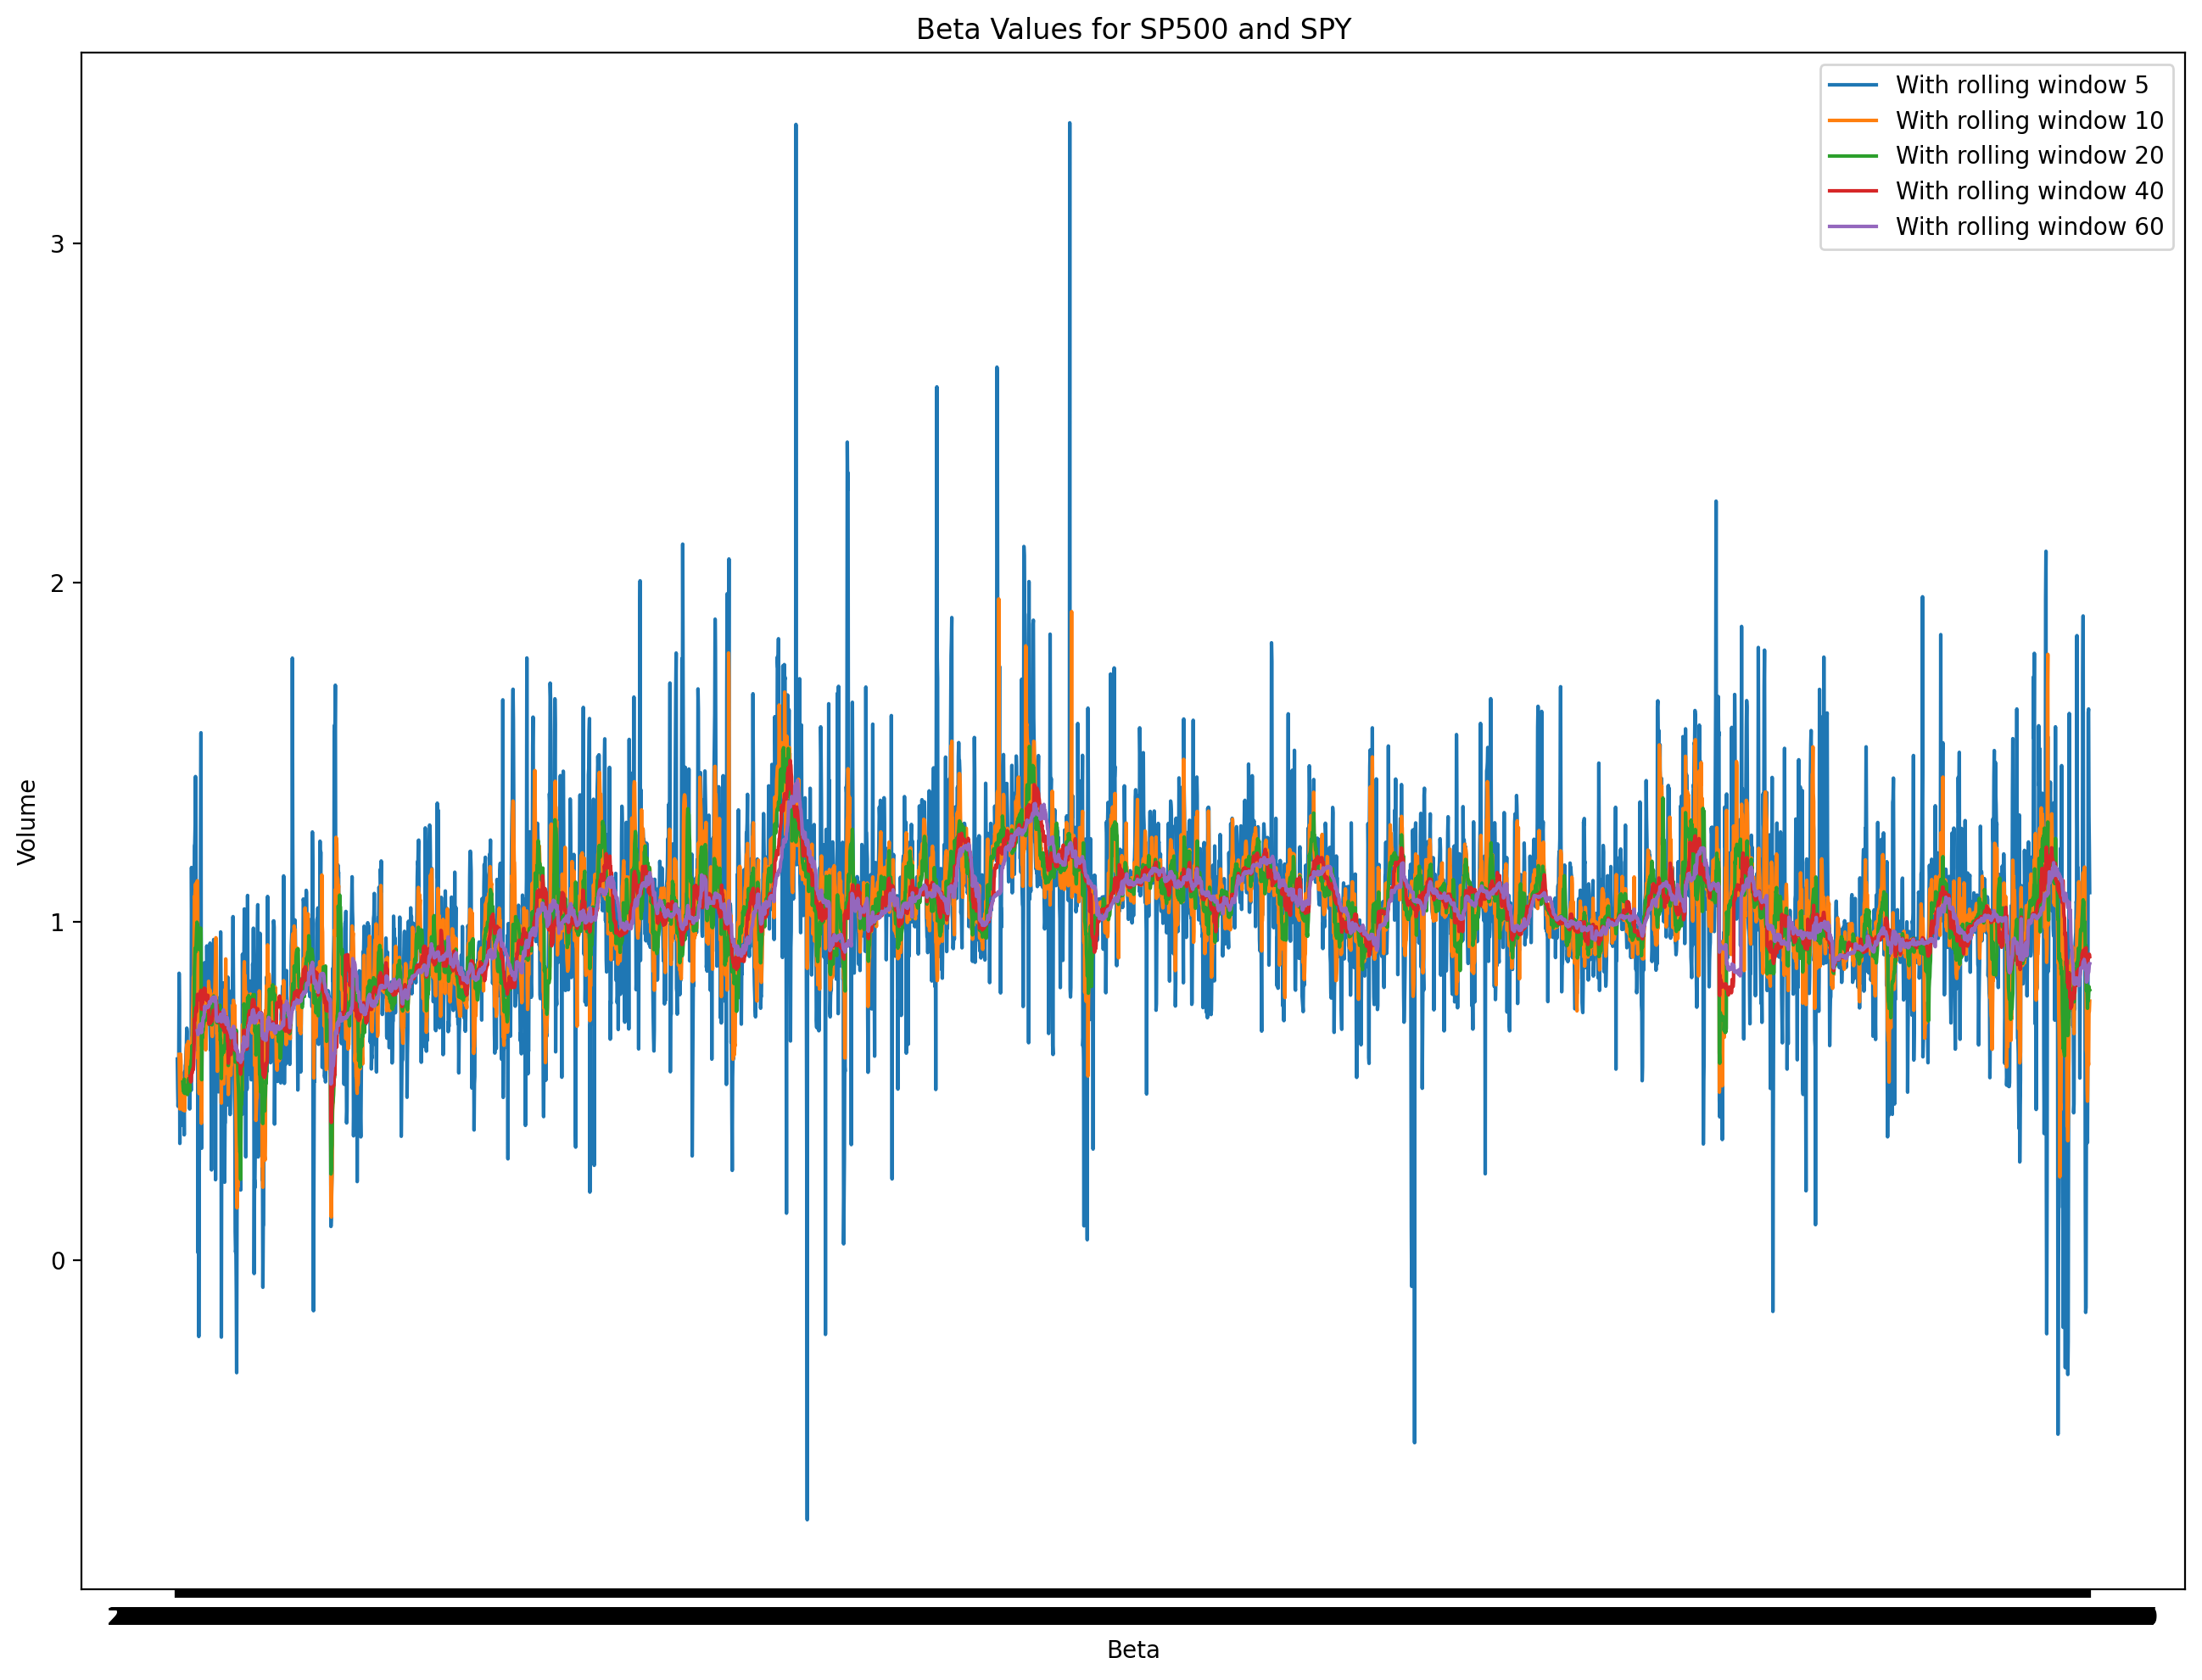

In [7]:
beta = SP_covariance / market_variance
print("Beta without rolling window")
print(beta.describe())

figure(num=None, figsize=(16, 12), dpi=200, facecolor='w', edgecolor='k')

for window in [5,10,20,40,60]:
    beta_df = daily_return_df.rolling(window=window).cov(daily_return_df['SPY']).div(daily_return_df['SPY'].rolling(window=window).var(), axis=0)
    plt.plot(beta_df.mean(axis='columns'), label = "With rolling window {0}".format(window))

plt.xlabel('Beta')
plt.ylabel('Volume')
plt.title("Beta Values for SP500 and SPY")
plt.legend()
plt.show()

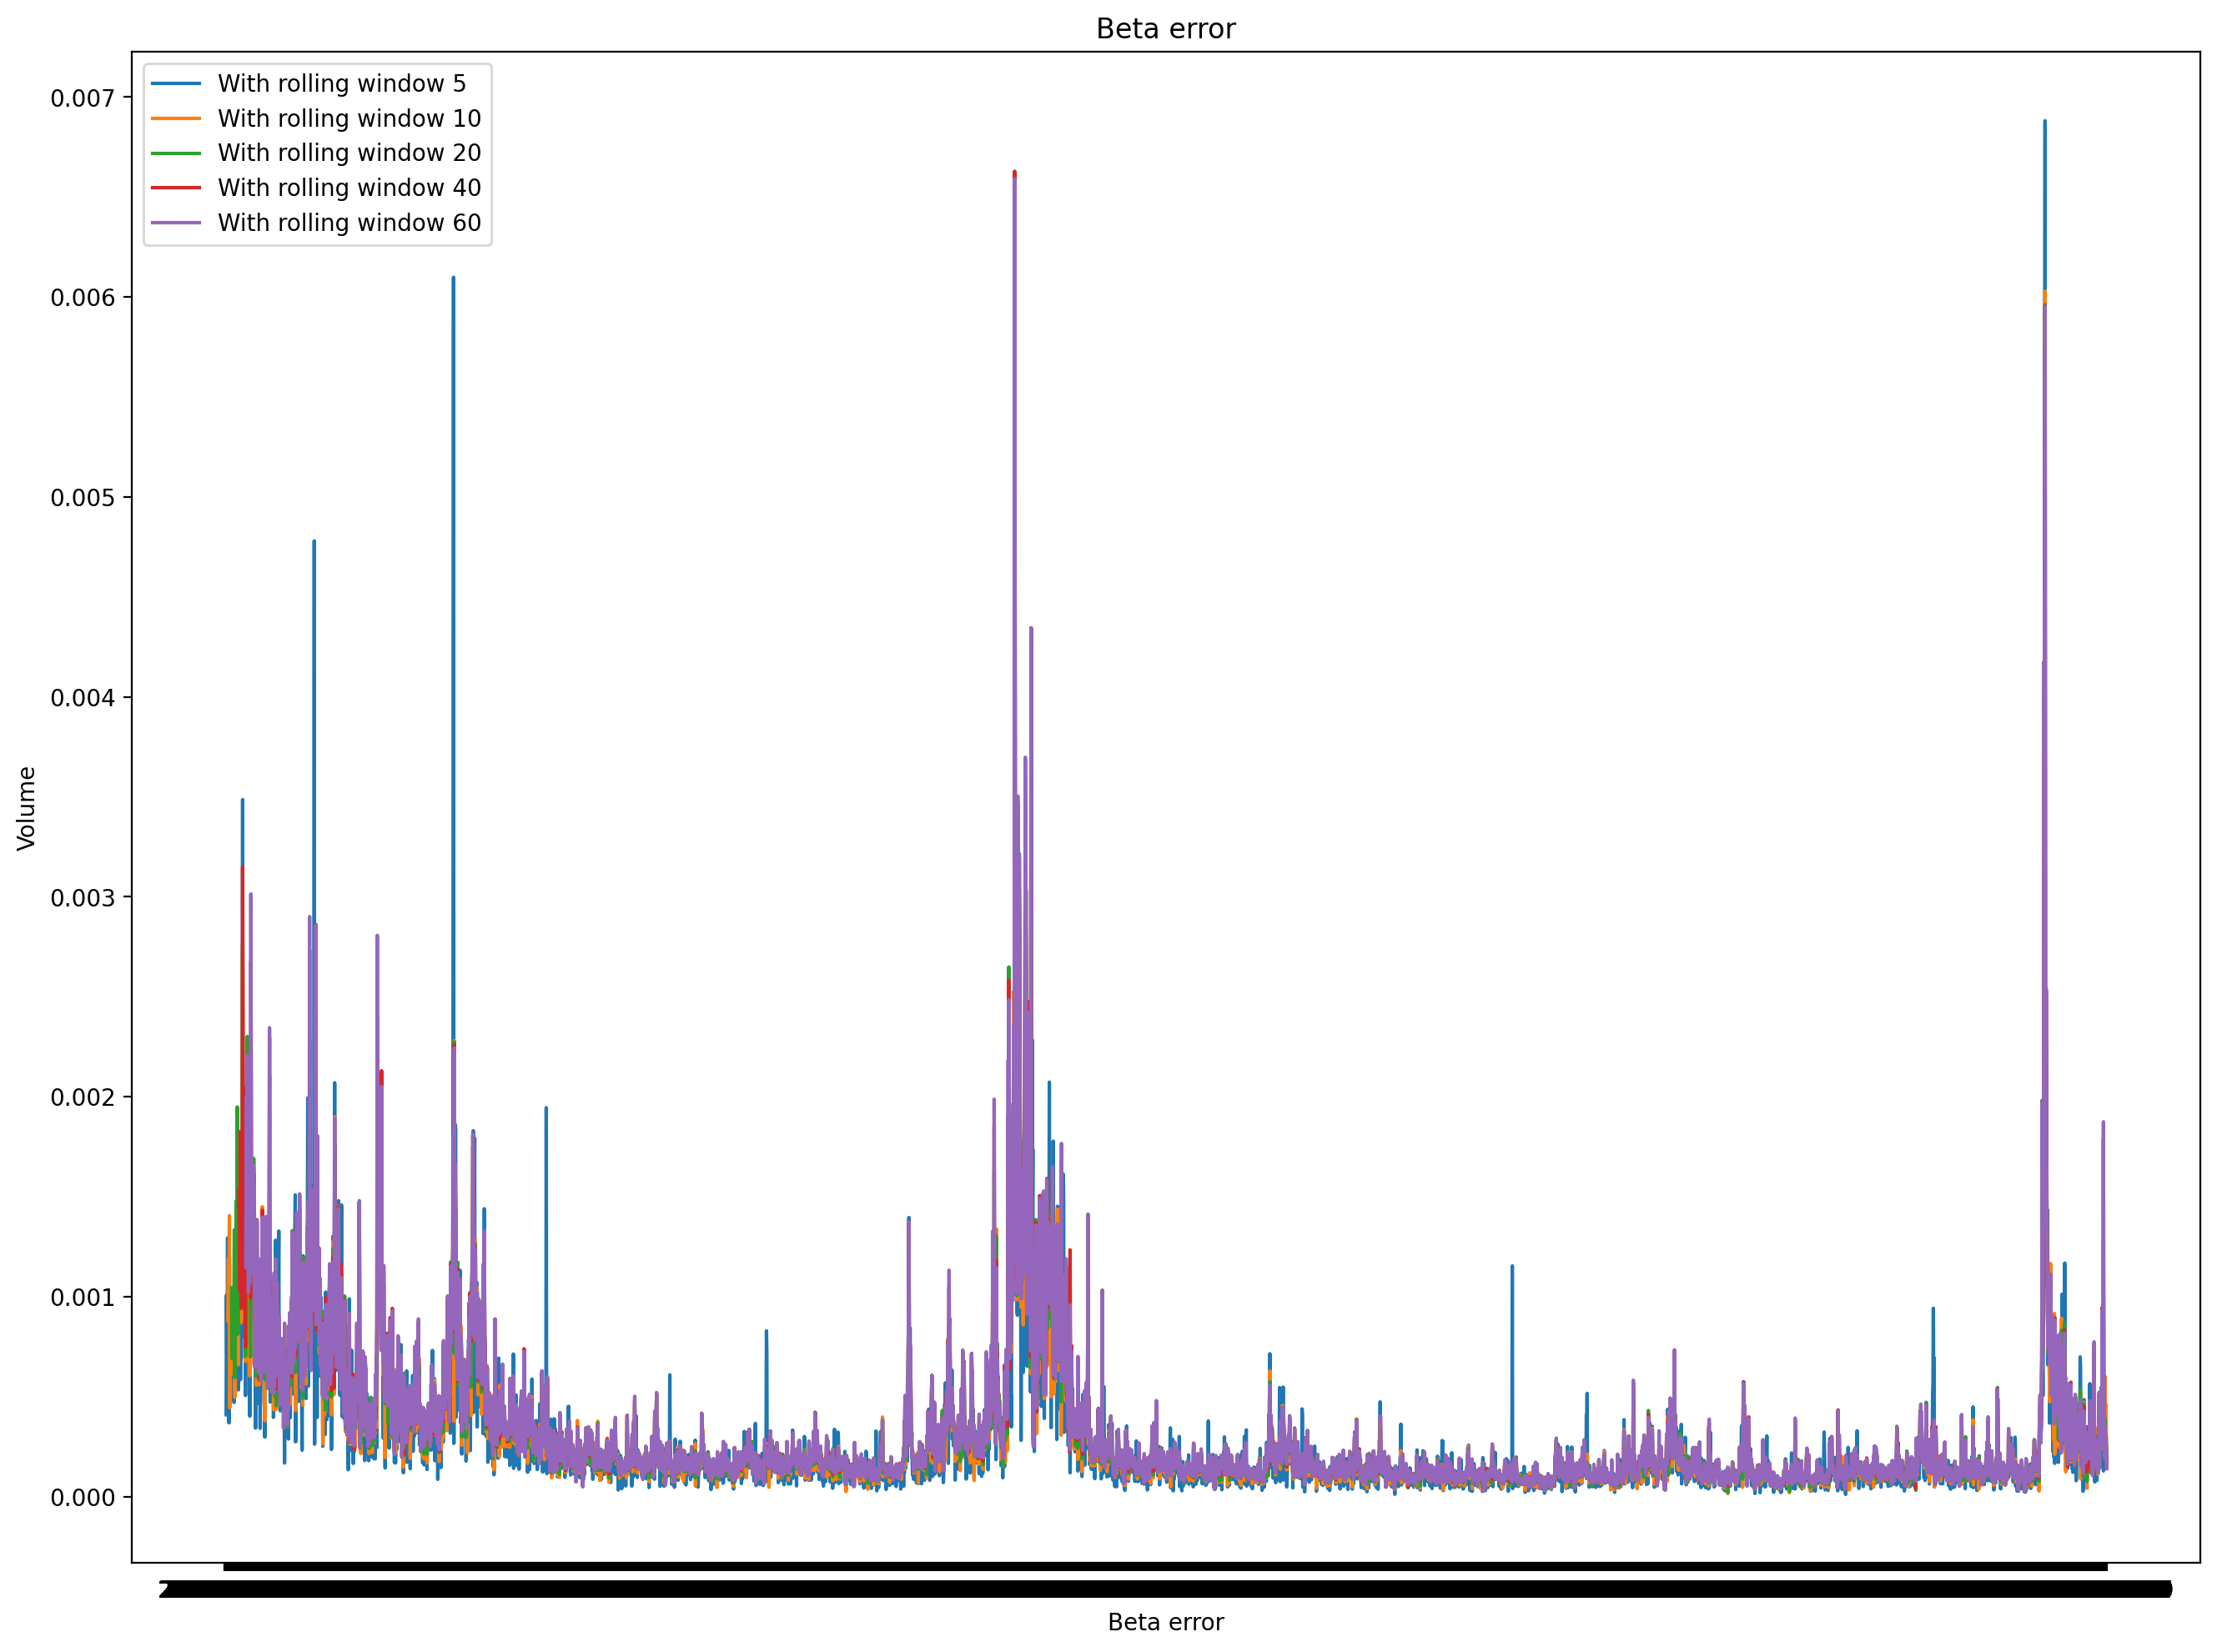

In [8]:
figure(num=None, figsize=(16, 12), dpi=200, facecolor='w', edgecolor='k')

for window in [5,10,20,40,60]:
    beta_df = daily_return_df.rolling(window=window).cov(daily_return_df['SPY']).div(daily_return_df['SPY'].rolling(window=window).var(), axis=0)
    beta_error_df = (daily_return_df - beta_df.mul(daily_return_df['SPY'], axis=0)) ** 2
    print("")
    plt.plot(beta_error_df.mean(axis='columns'), label = "With rolling window {0}".format(window))

plt.xlabel('Beta error')
plt.ylabel('Volume')
plt.title("Beta error")
plt.legend()
plt.show()

In [13]:
for window in [5,10,20,40,60]:
    beta_df = daily_return_df.rolling(window=window).cov(daily_return_df['SPY']).div(daily_return_df['SPY'].rolling(window=window).var(), axis=0)
    beta_error_df = (daily_return_df - beta_df.mul(daily_return_df['SPY'], axis=0)) ** 2
    print("Rolling window: {0}".format(window))
    mean_df = beta_error_df.mean(axis='columns')
    print("min: {0}, max: {1}, mean: {2}, deviation: {3}".format(mean_df.min(), mean_df.max(), mean_df.mean(), mean_df.std()))
    print(beta_error_df)

Rolling window: 5
min: 1.15343612466667e-05, max: 0.006881077089426752, mean: 0.00027897235003372347, deviation: 0.00037303733421369296
                     MMM       ABT      ABBV          ABMD           ACN  \
Date                                                                       
2000-01-03           NaN       NaN       NaN           NaN           NaN   
2000-01-04           NaN       NaN       NaN           NaN           NaN   
2000-01-05           NaN       NaN       NaN           NaN           NaN   
2000-01-06           NaN       NaN       NaN           NaN           NaN   
2000-01-07  5.265272e-06  0.000084       NaN  2.855909e-04           NaN   
...                  ...       ...       ...           ...           ...   
2020-11-16  2.255644e-06  0.000162  0.000334  4.200479e-05  6.513697e-06   
2020-11-17  1.243965e-06  0.000004  0.000007  1.913301e-07  9.944008e-07   
2020-11-18  5.741397e-08  0.000182  0.000014  2.962403e-06  1.197364e-06   
2020-11-19  5.010432e-06  0.

Rolling window: 40
min: 2.617455730887253e-05, max: 0.006628650587303144, mean: 0.0003033186700234022, deviation: 0.00038335367433690735
                     MMM       ABT      ABBV          ABMD           ACN  \
Date                                                                       
2000-01-03           NaN       NaN       NaN           NaN           NaN   
2000-01-04           NaN       NaN       NaN           NaN           NaN   
2000-01-05           NaN       NaN       NaN           NaN           NaN   
2000-01-06           NaN       NaN       NaN           NaN           NaN   
2000-01-07           NaN       NaN       NaN           NaN           NaN   
...                  ...       ...       ...           ...           ...   
2020-11-16  9.809542e-06  0.000121  0.000346  4.777087e-05  2.144609e-06   
2020-11-17  3.295389e-06  0.000008  0.000007  7.017927e-08  4.524937e-07   
2020-11-18  2.738789e-05  0.000529  0.000030  5.393151e-11  6.274444e-05   
2020-11-19  1.049346e-08  0